# Phase-4B — TrustFin-SLM Verifier-Aware Confidence Calibration and Selective Prediction

**Research objective:** The frozen E5 Qwen3-1.7B joint QLoRA model can generate executable FinQA programs, but executable programs can still be wrong. Phase-4A showed that correcting the answer by executing a program improves FinQA validation answer accuracy from **37.6% to 67.5%**. Raw model likelihood has only weak discrimination of correctness (~0.585 ROC-AUC on the designated calibration-fit records). We must test whether a modest **verifier-aware risk estimator** can better predict *when execution is trustworthy* and selectively abstain.

**Important:** This is *validation-development work*, not a new SLM fine-tuning run or protected test evaluation. All comparisons in this notebook are explicitly validation-only. FinTrust scoring is outside Phase-4B.

| ID | Experiment | Output |
|---|---|---|
| B1 | Raw generated-token likelihood | Confidence baseline and risk–coverage curve |
| B2 | Likelihood-only Platt/logistic model | Calibration improvement versus B1 |
| B3 | Verifier-aware logistic model | Likelihood + prompt length/truncation + syntactic/executable validity |
| B4 | Grounding-aware logistic model | B3 + recomputed numerical grounding features |
| B5 | Selective prediction | Fit-split coverage thresholds and holdout risk/coverage |
| B6 | FiQA regression error/uncertainty | Predict *absolute error*, selective MAE, empirical intervals |
| B7 | Reliability / AUC / Brier / ECE / AURC | Fit-OOF and holdout diagnostics |
| B8 | Phase-4B freeze | Fit-only model selection, immutable feature policy and test-safe handoff |

**Research safeguards:** The model's permitted predictors are explicitly whitelisted. `record_id` and `calibration_fold` serve only for alignment; gold answers, correctness labels, and errors are NEVER predictors. Hyperparameters and the winning policy are selected **from fit-split out-of-fold predictions**, before any holdout metrics are displayed. Holdout results are descriptive only; never reselect after inspecting them.

## How to run (students)

1. Obtain the successful Phase-4A package `Phase4A_Review_Package(1).zip` from the previous phase, or preserve its original `phase4b_interface/` and `labels/` folders.
2. Put the ZIP **beside this notebook**, or set `PHASE4A_ZIP` / `PHASE4A_DIR` in the configuration cell. The notebook automatically reads the original Phase-4A schema and checks IDs, folds, counts, feature leakage and source fingerprints.
3. Python 3.10+, `numpy`, `pandas`, `scipy`, `scikit-learn`, `matplotlib`, `joblib`, `nbformat` are sufficient. **No GPU required.** Run the optional installation cell only if dependencies are missing.
4. First set `RUN_MODE="smoke"` and execute **Kernel → Restart & Run All**. Smoke mode runs B1–B8 with fewer calibration-fit rows but **does not use the holdout** and **cannot freeze** the model.
5. Change to `RUN_MODE="full"` and restart/run all. The complete run uses 698 FinQA fit / 185 holdout and 92 FiQA fit / 25 holdout, with 5-fold (FinQA) and 4-fold (FiQA) OOF diagnostics. The defaults are CPU-friendly.
6. The notebook writes `artifacts/phase4b_full/`, including a `Phase4B_Review_Package.zip`. Do not manually edit `phase4b_freeze.json`, fit features or the holdout results.
7. **Run Phase-4C only after full-mode Phase-4B passes.** Phase-4C consumes the frozen B models/predictions; it does not tune on holdout.

**What to share:** Executed notebook, `Phase4B_Review_Package.zip`, `phase4b_freeze.json`, `phase4b_readiness.json`, `B7_model_diagnostics.csv`, `B5_risk_coverage.csv`, `B6_fiqa_uncertainty.csv`. Do **not** upload private financial source documents or checkpoint weights unless specifically necessary.

In [1]:
INSTALL_DEPS = False
if INSTALL_DEPS:
    import sys, subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-U',
        'numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib', 'joblib', 'nbformat'])
    print('Restart the kernel once after installation.')
else:
    print('Using the current Python environment.')

Using the current Python environment.


## 1. Configuration, imports, deterministic execution

In [2]:
import os, io, json, zipfile, hashlib, time, platform, warnings
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_predict
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss, mean_absolute_error, mean_squared_error
import joblib

RUN_MODE = os.environ.get('TRUSTFIN_RUN_MODE','full').lower()  # 'smoke' or 'full'
SEED = 42
WORKSPACE_ROOT = Path(os.environ.get('TRUSTFIN_WORKSPACE',str(Path.cwd()))).expanduser().resolve()
PHASE4A_ZIP = os.environ.get('TRUSTFIN_PHASE4A_ZIP','')
PHASE4A_DIR = os.environ.get('TRUSTFIN_PHASE4A_DIR','')
OUTPUT_ROOT = WORKSPACE_ROOT/'artifacts'/('phase4b_full' if RUN_MODE=='full' else 'phase4b_smoke')
for child in ['tables','predictions','models','plots','manifests','reviews']:
    (OUTPUT_ROOT/child).mkdir(parents=True,exist_ok=True)
assert RUN_MODE in {'smoke','full'}
rng=np.random.default_rng(SEED)
print('Phase-4B', RUN_MODE, 'Workspace:', WORKSPACE_ROOT)

Phase-4B full Workspace: /home/heet18/Downloads/Research Papers/notebooks


## 2. Read the exact Phase-4A data contract (ZIP or extracted folder)

In [3]:
REQUIRED = {
    'finqa_features':'phase4b_interface/phase4b_finqa_features.jsonl',
    'fiqa_features':'phase4b_interface/phase4b_fiqa_features.jsonl',
    'finqa_labels':'labels/phase4b_finqa_labels.jsonl',
    'fiqa_labels':'labels/phase4b_fiqa_labels.jsonl',
    'policy':'phase4b_interface/phase4b_feature_policy.json',
    'readiness':'manifests/phase4a_readiness.json',
}
def sha(raw):return hashlib.sha256(raw).hexdigest()
def locate_source():
    if PHASE4A_DIR:
        p=Path(PHASE4A_DIR).expanduser()
        if all((p/v).is_file() for v in REQUIRED.values()):return 'directory',p
    if PHASE4A_ZIP:
        p=Path(PHASE4A_ZIP).expanduser()
        if p.is_file():return 'zip',p
    for p in [WORKSPACE_ROOT/'Phase4A_Review_Package(1).zip',WORKSPACE_ROOT/'Phase4A_Review_Package.zip',
              Path.cwd()/'Phase4A_Review_Package(1).zip',Path.cwd()/'Phase4A_Review_Package.zip',
              Path('/mnt/data/Phase4A_Review_Package(1).zip')]:
        if p.is_file():return 'zip',p
    for p in [WORKSPACE_ROOT/'artifacts/phase4a',WORKSPACE_ROOT/'phase4a_user_review',Path('/mnt/data/phase4a_user_review')]:
        if all((p/v).is_file() for v in REQUIRED.values()):return 'directory',p
    raise FileNotFoundError('Phase-4A inputs missing: set TRUSTFIN_PHASE4A_ZIP or TRUSTFIN_PHASE4A_DIR')
SOURCE_KIND,SOURCE_PATH=locate_source()
SOURCE_HASHES={}
def read_source(key):
    rel=REQUIRED[key]
    if SOURCE_KIND=='directory': raw=(SOURCE_PATH/rel).read_bytes()
    else:
        with zipfile.ZipFile(SOURCE_PATH) as z:
            matches=[n for n in z.namelist() if n==rel or n.endswith('/'+rel)]
            if len(matches)!=1:raise ValueError(f'Exactly one {rel} is required; found {matches}')
            raw=z.read(matches[0])
    SOURCE_HASHES[key]=sha(raw)
    return raw
def load_jsonl(k):return pd.DataFrame([json.loads(line) for line in read_source(k).decode().splitlines() if line.strip()])
def save_json(name,obj):
    p=OUTPUT_ROOT/'manifests'/name
    p.write_text(json.dumps(obj,indent=2,default=str),encoding='utf-8');return p
policy=json.loads(read_source('policy'))
phase4a_readiness=json.loads(read_source('readiness'))
print('Source:',SOURCE_KIND,SOURCE_PATH)
print('Phase4A readiness:', phase4a_readiness.get('core_phase4a_status'),
      phase4a_readiness.get('research_full_grounding_status'))
assert phase4a_readiness.get('core_phase4a_status')=='PASS'

Source: zip /home/heet18/Downloads/Research Papers/notebooks/Phase4A_Review_Package.zip
Phase4A readiness: PASS PASS


## 3. Split integrity, predictors whitelist, and label-leakage firewall

In [4]:
F=load_jsonl('finqa_features'); FL=load_jsonl('finqa_labels')
Q=load_jsonl('fiqa_features'); QL=load_jsonl('fiqa_labels')
def validate_pair(X,Y,dataset,n):
    assert len(X)==len(Y)==n, (dataset,len(X),len(Y))
    assert X.record_id.is_unique and Y.record_id.is_unique
    assert set(X.record_id)==set(Y.record_id)
    assert set(X.calibration_fold)==set(Y.calibration_fold)=={'calibration_fit','calibration_holdout'}
    # One-to-one joins only; do not bring gold labels into the predictor frame.
    cross=X[['record_id','calibration_fold']].merge(Y[['record_id','calibration_fold']],on='record_id',validate='one_to_one',suffixes=('_X','_Y'))
    assert (cross.calibration_fold_X==cross.calibration_fold_Y).all()
    assert (X.dataset==dataset).all()
validate_pair(F,FL,'FinQA',883);validate_pair(Q,QL,'FiQA',117)
assert Counter(F.calibration_fold)=={'calibration_fit':698,'calibration_holdout':185}
assert Counter(Q.calibration_fold)=={'calibration_fit':92,'calibration_holdout':25}
forbidden=set(policy['forbidden_feature_names']) | {'dataset','calibration_fold','record_id', 'mean_token_logprob'}
for field in ['execution_correct','written_correct','corrected_correct','gold_sentiment','absolute_error']:
    assert field not in F.columns and field not in Q.columns
FINQA_SETS={
   'B1_raw':['source_likelihood'],
   'B2_likelihood':['source_likelihood'],
   'B3_verifier':['source_likelihood','prompt_tokens','prompt_truncation_observed','official_executable_feature','program_structural_valid'],
   'B4_grounding':['source_likelihood','prompt_tokens','prompt_truncation_observed','official_executable_feature','program_structural_valid',
                   'any_literal_unmatched','unmatched_literal_count','literal_presence_fraction','max_question_local_overlap'],
}
FIQA_FEATURES=['source_likelihood','generated_tokens','prompt_tokens','sentiment_pred_clipped','score_near_boundary','parse_ok']
for name, features in [*FINQA_SETS.items(),('FiQA',FIQA_FEATURES)]:
    df=Q if name=='FiQA' else F
    assert set(features).issubset(df.columns), (name,set(features)-set(df.columns))
    assert not (set(features)&forbidden), (name,set(features)&forbidden)
    assert all(pd.api.types.is_numeric_dtype(df[f]) for f in features)
assert phase4a_readiness.get('research_full_grounding_status')=='PASS', 'Grounding must be recomputed by Phase-4A before B4.'
print('PASS: feature/label separation; 698/185 and 92/25 protected calibration splits.')

PASS: feature/label separation; 698/185 and 92/25 protected calibration splits.


## 4. Sampling and evaluation utilities (only fit split may select models)

In [5]:
Xf=F.set_index('record_id',drop=False); Yf=FL.set_index('record_id',drop=False)
Xq=Q.set_index('record_id',drop=False); Yq=QL.set_index('record_id',drop=False)
yf=Yf.reindex(Xf.index)['execution_correct'].astype(int)
yq=Yq.reindex(Xq.index)['absolute_error'].astype(float)
f_fit=(Xf.calibration_fold=='calibration_fit'); f_hold=~f_fit
q_fit=(Xq.calibration_fold=='calibration_fit'); q_hold=~q_fit
if RUN_MODE=='smoke':
    # Smoke only uses calibration_fit, never the real calibration_holdout.
    original_f_ids=Xf[f_fit].sample(frac=1,random_state=SEED).index
    original_q_ids=Xq[q_fit].sample(frac=1,random_state=SEED).index
    f_fit=Xf.index.isin(original_f_ids[:120])
    f_hold=Xf.index.isin(original_f_ids[120:150])
    q_fit=Xq.index.isin(original_q_ids[:48])
    q_hold=Xq.index.isin(original_q_ids[48:60])
def logistic(features):
    return Pipeline([('impute',SimpleImputer(strategy='median',add_indicator=False)),
        ('scale',StandardScaler()),('model',LogisticRegression(C=1.0,max_iter=1200,random_state=SEED))])
def regression(features):
    return Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler()),('model',Ridge(alpha=10.0))])
def roc(y,p):return float(roc_auc_score(y,p)) if len(np.unique(y))>1 else float('nan')
def ece(y,p,bins=10):
    y=np.asarray(y);p=np.clip(np.asarray(p),0,1)
    edges=np.linspace(0,1,bins+1);err=0.
    for i in range(bins):
        sel=(p>=edges[i]) & ((p<edges[i+1]) if i<bins-1 else (p<=edges[i+1]))
        if sel.any(): err+=sel.mean()*abs(y[sel].mean()-p[sel].mean())
    return float(err)
def rc_curve(correct,score):
    correct=np.asarray(correct,dtype=float);score=np.asarray(score,dtype=float)
    score=np.nan_to_num(score,nan=-1e10); order=np.argsort(-score,kind='stable')
    err=1-correct[order]; cover=np.arange(1,len(err)+1)/len(err)
    risk=np.cumsum(err)/np.arange(1,len(err)+1)
    return cover,risk
def aurc(correct,score):
    c,r=rc_curve(correct,score)
    return float(np.mean(r)) # discrete coverage-integrated risk
def classification_metrics(y,p):
    y=np.asarray(y).astype(int);p=np.clip(np.asarray(p,dtype=float),1e-6,1-1e-6)
    return {'n':len(y),'roc_auc':roc(y,p),'brier':float(brier_score_loss(y,p)),
            'ece10':ece(y,p),'nll':float(log_loss(y,p,labels=[0,1])),
            'aurc':aurc(y,p)}
def fit_threshold(scores,goal):
    scores=np.asarray(scores,dtype=float)
    # Conservative cutoff computed from fit predictions only. Ties can alter actual coverage.
    return float(np.quantile(scores,1-goal))
def selective_stats(correct,score,threshold,valid_mask=None):
    correct=np.asarray(correct,dtype=int);score=np.asarray(score,dtype=float)
    accept=np.isfinite(score)&(score>=threshold)
    if valid_mask is not None: accept &= np.asarray(valid_mask,dtype=bool)
    return {'n':len(correct),'accepted':int(accept.sum()),'coverage':float(accept.mean()),
            'selective_risk':float(np.mean(1-correct[accept])) if accept.any() else float('nan'),
            'selective_accuracy':float(np.mean(correct[accept])) if accept.any() else float('nan')},accept
print('FinQA fit',int(f_fit.sum()),'holdout',int(f_hold.sum()),
      '| FiQA fit',int(q_fit.sum()),'holdout',int(q_hold.sum()))

FinQA fit 698 holdout 185 | FiQA fit 92 holdout 25


## 5. B1–B4: Out-of-fold development; **freeze selection before holdout**

In [6]:
fit_X=Xf.loc[f_fit];fit_y=yf.loc[f_fit].to_numpy()
folds=StratifiedKFold(n_splits=5 if RUN_MODE=='full' else 3,shuffle=True,random_state=SEED)
models={};fit_scores={};dev_rows=[]
for name,feat in FINQA_SETS.items():
    if name=='B1_raw':
        prob=np.clip(fit_X['source_likelihood'].to_numpy(dtype=float),1e-6,1-1e-6)
        models[name]=None
    else:
        mdl=logistic(feat)
        prob=cross_val_predict(mdl,fit_X[feat],fit_y,cv=folds,method='predict_proba')[:,1]
        mdl.fit(fit_X[feat],fit_y)
        models[name]=mdl
    fit_scores[name]=prob
    m=classification_metrics(fit_y,prob)
    dev_rows.append({'method':name,'partition':'fit_oof',**m,'n_features':len(feat)})
dev=pd.DataFrame(dev_rows).sort_values(['aurc','brier','method'])
dev.to_csv(OUTPUT_ROOT/'tables/B1_B4_fit_oof_comparison.csv',index=False)
display(dev)
# PRE-COMMITTED selection -- strictly fit-OOF AURC; no holdout results seen.
WINNER=str(dev.iloc[0]['method'])
TARGET_COVERAGE=0.80
thresholds={name:fit_threshold(p,TARGET_COVERAGE) for name,p in fit_scores.items()}
FROZEN_SELECTION={'winner':WINNER,'criteria':'minimum fit-OOF AURC, Brier as tie-breaker',
    'target_coverage':TARGET_COVERAGE,'thresholds_from_fit_oof':thresholds,
    'feature_sets':FINQA_SETS,'no_label_features':True,'fit_sample_count':len(fit_y),
    'seed':SEED,'run_mode':RUN_MODE,'holdout_not_used_for_selection':True,
    'grounding_source':phase4a_readiness.get('research_full_grounding_status')}
save_json('B8_fit_only_selection.json',FROZEN_SELECTION)
for name,mdl in models.items():
    if mdl is not None:joblib.dump(mdl,OUTPUT_ROOT/'models'/f'{name}.joblib')
print('FROZEN FROM FIT OOF BEFORE HOLDOUT:',WINNER, 'target coverage:',TARGET_COVERAGE)

,method,partition,n,roc_auc,brier,ece10,nll,aurc,n_features
0,B1_raw,fit_oof,698,0.584507,0.264607,0.226956,0.915801,0.240336,1
1,B2_likelihood,fit_oof,698,0.583305,0.212894,0.046058,0.616508,0.243642,1
2,B3_verifier,fit_oof,698,0.574315,0.210882,0.027643,0.612101,0.265262,5
3,B4_grounding,fit_oof,698,0.588141,0.207128,0.008736,0.602216,0.267261,9


FROZEN FROM FIT OOF BEFORE HOLDOUT: B1_raw target coverage: 0.8


## 6. B5, B7: One-time FinQA holdout evaluation, reliability and selective curves

,method,partition,n,roc_auc,brier,ece10,nll,aurc,n_features
0,B1_raw,fit_oof,698,0.584507,0.264607,0.226956,0.915801,0.240336,1.0
1,B2_likelihood,fit_oof,698,0.583305,0.212894,0.046058,0.616508,0.243642,1.0
2,B3_verifier,fit_oof,698,0.574315,0.210882,0.027643,0.612101,0.265262,5.0
3,B4_grounding,fit_oof,698,0.588141,0.207128,0.008736,0.602216,0.267261,9.0
4,B1_raw,holdout,185,0.545641,0.299643,0.267621,1.042031,0.287875,NaN
5,B2_likelihood,holdout,185,0.545641,0.230525,0.042212,0.653776,0.287875,NaN
6,B3_verifier,holdout,185,0.570000,0.225098,0.040425,0.641843,0.284868,NaN
7,B4_grounding,holdout,185,0.551026,0.222784,0.069920,0.637145,0.324530,NaN


,method,partition,requested_coverage,frozen_fit_threshold,n,accepted,coverage,selective_risk,selective_accuracy
2,B1_raw,holdout,0.8,0.847279,185,151,0.816216,0.350993,0.649007
7,B2_likelihood,holdout,0.8,0.635270,185,151,0.816216,0.350993,0.649007
12,B3_verifier,holdout,0.8,0.630475,185,144,0.778378,0.333333,0.666667
17,B4_grounding,holdout,0.8,0.644285,185,147,0.794595,0.326531,0.673469


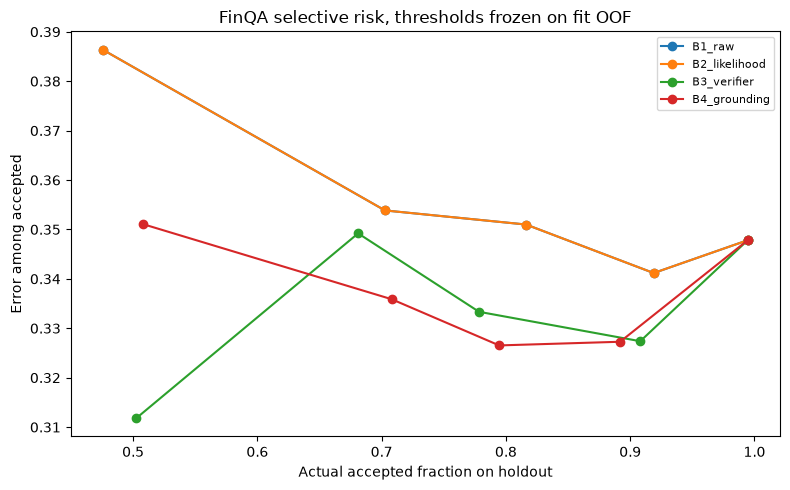

In [7]:
hold_X=Xf.loc[f_hold];hold_y=yf.loc[f_hold].to_numpy()
hold_rows=[]; pred_rows=[];curve_rows=[]
for name,feat in FINQA_SETS.items():
    if name=='B1_raw': hp=np.clip(hold_X.source_likelihood.to_numpy(dtype=float),1e-6,1-1e-6)
    else: hp=models[name].predict_proba(hold_X[feat])[:,1]
    pred_rows.extend([{'record_id':rid,'dataset':'FinQA','calibration_fold':'calibration_holdout',
         'method':name,'p_correct':float(p)} for rid,p in zip(hold_X.index,hp)])
    hold_rows.append({'method':name,'partition':'holdout',**classification_metrics(hold_y,hp)})
    # Fixed fit-side thresholds at target coverages; empirical holdout coverages may vary.
    for coverage in [0.50,0.70,0.80,0.90,1.00]:
        cutoff=fit_threshold(fit_scores[name],coverage) if coverage<1 else float('-inf')
        hard_gate=(hold_X['official_executable_feature'].astype(bool)&
                   hold_X['program_structural_valid'].astype(bool)).to_numpy()
        stats,accepted=selective_stats(hold_y,hp,cutoff,hard_gate)
        curve_rows.append({'method':name,'partition':'holdout','requested_coverage':coverage,
                           'frozen_fit_threshold':cutoff,**stats})
B7=pd.concat([dev,pd.DataFrame(hold_rows)],ignore_index=True,sort=False)
B7.to_csv(OUTPUT_ROOT/'tables/B7_model_diagnostics.csv',index=False)
PD=pd.DataFrame(pred_rows);PD.to_csv(OUTPUT_ROOT/'predictions/B1_B4_finqa_holdout_scores.csv',index=False)
B5=pd.DataFrame(curve_rows)
B5.to_csv(OUTPUT_ROOT/'tables/B5_risk_coverage.csv',index=False)
display(B7);display(B5.query('requested_coverage==0.8'))
fig,ax=plt.subplots(figsize=(8,5))
for name,g in B5.groupby('method'):
    ax.plot(g.coverage,g.selective_risk,marker='o',label=name)
ax.set(xlabel='Actual accepted fraction on holdout',ylabel='Error among accepted',
       title='FinQA selective risk, thresholds frozen on fit OOF')
ax.legend(fontsize=8);fig.tight_layout();fig.savefig(OUTPUT_ROOT/'plots/B5_finqa_risk_coverage.png',dpi=180);plt.show()

## 7. B6: FiQA-specific error-risk estimation and *empirical* uncertainty

In [8]:
qX=Xq.loc[q_fit]; qy=yq.loc[q_fit].to_numpy(dtype=float)
q_cv=KFold(n_splits=4 if RUN_MODE=='full' else 3,shuffle=True,random_state=SEED)
fiqa_model=regression(FIQA_FEATURES)
q_oof=cross_val_predict(fiqa_model,qX[FIQA_FEATURES],qy,cv=q_cv,method='predict')
q_oof=np.maximum(q_oof,0)
fiqa_model.fit(qX[FIQA_FEATURES],qy)
qH=Xq.loc[q_hold]; qY=yq.loc[q_hold].to_numpy(dtype=float)
q_hat=np.maximum(fiqa_model.predict(qH[FIQA_FEATURES]),0)
q_base=np.repeat(float(np.mean(qy)),len(qY))
q_likelihood=qH['source_likelihood'].to_numpy(dtype=float)
q_methods={'B6_constant':-q_base,'B6_likelihood':q_likelihood,'B6_ridge_error':-q_hat}
q_goal=0.8
q_risks=[];q_pred=[]
fit_risk={'B6_constant':-np.repeat(float(np.mean(qy)),len(qy)),
          'B6_likelihood':qX['source_likelihood'].to_numpy(dtype=float),
          'B6_ridge_error':-q_oof}
for name,score in q_methods.items():
    thresh=fit_threshold(fit_risk[name],q_goal)
    ok=np.isfinite(score)&(score>=thresh)
    ok &= qH['parse_ok'].to_numpy(dtype=int)==1
    q_risks.append({'method':name,'partition':'holdout','requested_coverage':q_goal,
                    'coverage':float(ok.mean()),'accepted':int(ok.sum()),
                    'selective_mae':float(np.mean(qY[ok])) if ok.any() else float('nan'),
                    'full_mae':float(np.mean(qY)),'spearman_score_negative_error':float(spearmanr(score,-qY).statistic)})
    for rid,s,pred_e,accept in zip(qH.index,score,q_hat,ok):
        q_pred.append({'record_id':rid,'method':name,'uncertainty_score':float(s),
                       'expected_absolute_error':float(pred_e),'accept_80pct':bool(accept)})
# Descriptive error interval: quantile of fit-side OOF absolute errors. This is NOT formal conformal coverage.
q_radius=float(np.quantile(qy,0.90))
q_predscore=qH['sentiment_pred_clipped'].to_numpy(dtype=float)
ygold=qH['sentiment_pred_clipped'].to_numpy(dtype=float) - 0 # true score stays in labels
q_gold=QL.set_index('record_id').loc[qH.index,'gold_sentiment'].to_numpy(dtype=float)
interval_lo=np.clip(q_predscore-q_radius,-1,1);interval_hi=np.clip(q_predscore+q_radius,-1,1)
empirical_coverage=float(np.mean((q_gold>=interval_lo)&(q_gold<=interval_hi)))
B6=pd.DataFrame(q_risks);B6.to_csv(OUTPUT_ROOT/'tables/B6_fiqa_uncertainty.csv',index=False)
pd.DataFrame(q_pred).to_csv(OUTPUT_ROOT/'predictions/B6_fiqa_holdout_scores.csv',index=False)
joblib.dump(fiqa_model,OUTPUT_ROOT/'models/B6_fiqa_error_ridge.joblib')
FIQA_FREEZE={'features':FIQA_FEATURES,'alpha':10.0,'target':'absolute_error',
             'fit_oof_90th_percentile_absolute_error':q_radius,
             'holdout_empirical_interval_coverage':empirical_coverage,
             'interval_guarantee':'none; descriptive fit OOF quantile, not formal conformal prediction',
             'target_coverage':q_goal,'fit_thresholds':{k:fit_threshold(v,q_goal) for k,v in fit_risk.items()}}
save_json('B6_fiqa_policy.json',FIQA_FREEZE)
display(B6)
print('FiQA empirical interval coverage (diagnostic only):',round(empirical_coverage,3))

/tmp/ipykernel_136270/384557662.py:24: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  'full_mae':float(np.mean(qY)),'spearman_score_negative_error':float(spearmanr(score,-qY).statistic)})


,method,partition,requested_coverage,coverage,accepted,selective_mae,full_mae,spearman_score_negative_error
0,B6_constant,holdout,0.8,1.00,25,0.124480,0.12448,NaN
1,B6_likelihood,holdout,0.8,0.76,19,0.101000,0.12448,0.038462
2,B6_ridge_error,holdout,0.8,0.72,18,0.132778,0.12448,0.123846


FiQA empirical interval coverage (diagnostic only): 0.96


## 8. B8 freeze, regression tests and downstream Phase-4C interface

In [9]:
GATES={
   'phase4a_core_pass':phase4a_readiness.get('core_phase4a_status')=='PASS',
   'phase4a_grounding_recomputed':phase4a_readiness.get('research_full_grounding_status')=='PASS',
   'finqa_record_alignment':len(F)==len(FL)==883 and Xf.index.is_unique,
   'fiqa_record_alignment':len(Q)==len(QL)==117 and Xq.index.is_unique,
   'fit_holdout_fixed':Counter(F.calibration_fold)=={'calibration_fit':698,'calibration_holdout':185}
                          and Counter(Q.calibration_fold)=={'calibration_fit':92,'calibration_holdout':25},
   'fit_only_winner_frozen':(OUTPUT_ROOT/'manifests/B8_fit_only_selection.json').exists(),
   'no_gold_in_features':all(not (set(x)&forbidden) for x in FINQA_SETS.values())
                          and not(set(FIQA_FEATURES)&forbidden),
   'all_B1_to_B8_outputs_present':all((OUTPUT_ROOT/sub/name).exists() for sub,name in [
      ('tables','B1_B4_fit_oof_comparison.csv'),('tables','B7_model_diagnostics.csv'),
      ('tables','B5_risk_coverage.csv'),('tables','B6_fiqa_uncertainty.csv'),
      ('predictions','B1_B4_finqa_holdout_scores.csv'),('predictions','B6_fiqa_holdout_scores.csv'),
      ('manifests','B6_fiqa_policy.json'),('manifests','B8_fit_only_selection.json')]),
}
passed=bool(all(GATES.values()))
readiness={'phase':'Phase-4B','run_mode':RUN_MODE,
    'status':'PASS_FROZEN' if passed and RUN_MODE=='full' else 'SMOKE_NOT_FROZEN' if passed else 'FAIL',
    'gates':GATES,'fit_selection_winner':WINNER,
    'holdout_never_used_to_select_winner':True,
    'protected_test_sets_used':False,
    'limitations':['The 185/25 holdouts are internal validation, not protected test sets.',
                   'FiQA interval is descriptive; do not claim formal conformal guarantee.',
                   'Source-based numerical presence is not semantic grounding.',
                   'Do not retune based on these holdout outputs.']}
save_json('phase4b_readiness.json',readiness)
freeze={'schema':'trustfin.phase4b.v1','status':readiness['status'],
    'source_phase4a':str(SOURCE_PATH),'source_sha256':sha(SOURCE_PATH.read_bytes()) if SOURCE_KIND=='zip' else None,
    'source_component_hashes':SOURCE_HASHES,'winner_from_fit_oof':WINNER,
    'fit_only_selection':FROZEN_SELECTION,'fiqa_uncertainty_policy':FIQA_FREEZE,
    'seed':SEED,'models':{k:str((OUTPUT_ROOT/'models'/f'{k}.joblib').resolve()) if k!='B1_raw' else None for k in FINQA_SETS},
    'reports_relative_to_output_root':{'holdout_scores':'predictions/B1_B4_finqa_holdout_scores.csv',
                                     'fiqa_scores':'predictions/B6_fiqa_holdout_scores.csv',
                                     'holdout_metrics':'tables/B7_model_diagnostics.csv',
                                     'risk_coverage':'tables/B5_risk_coverage.csv'},
    'holdout_was_not_used_for_model_or_threshold_selection':True}
save_json('phase4b_freeze.json',freeze)
# Data-agnostic production feature contract: no gold answers or validation-only correctness labels.
save_json('phase4c_handoff.json',{'schema':'trustfin.phase4c.v1','phase4b_root':str(OUTPUT_ROOT),
     'phase4b_freeze':'manifests/phase4b_freeze.json',
     'phase4a_source':str(SOURCE_PATH),'source_kind':SOURCE_KIND,
     'finqa_feature_sets':FINQA_SETS,'fiqa_features':FIQA_FEATURES,
     'no_protected_test':True})
import zipfile
pkg=OUTPUT_ROOT/'Phase4B_Review_Package.zip'
with zipfile.ZipFile(pkg,'w',zipfile.ZIP_DEFLATED) as z:
    for file in sorted(OUTPUT_ROOT.rglob('*')):
        if file.is_file() and file!=pkg and file.suffix!='.joblib':
            z.write(file,file.relative_to(OUTPUT_ROOT))
print('STATUS:',readiness['status'],'Winner:',WINNER,'Package:',pkg)
assert passed, GATES

STATUS: PASS_FROZEN Winner: B1_raw Package: /home/heet18/Downloads/Research Papers/notebooks/artifacts/phase4b_full/Phase4B_Review_Package.zip


## Phase-4B: outputs to share before Phase-4C research review

**Mandatory:** executed `.ipynb`, `Phase4B_Review_Package.zip`, `manifests/phase4b_readiness.json`, `manifests/phase4b_freeze.json`, `tables/B1_B4_fit_oof_comparison.csv`, `tables/B7_model_diagnostics.csv`, `tables/B5_risk_coverage.csv`, and `tables/B6_fiqa_uncertainty.csv`.

**Keep locally for future protected-test inference:** `models/B2_likelihood.joblib`, `models/B3_verifier.joblib`, `models/B4_grounding.joblib`, `models/B6_fiqa_error_ridge.joblib`, plus the frozen Phase-3 E5 checkpoint. Only load serialized models from trusted sources.

**Research decision:** A Phase-4B `PASS_FROZEN` status means the calibration protocol executed and selection was fit-only. It **does not** guarantee the chosen risk model improved on likelihood-only. Interpret results before claiming added novelty.